# Variational Quantum Classifier (VQC) — road patch classification

**Smart Traffic Complaint & Monitoring System · QML workstream (Avyukt)**

Same task and same data as `classical_baseline.ipynb`: classify road patches as Cracks / Normal / Pothole.

Contents
1. Check the simulator (against brute-force matrices; optionally against PennyLane)
2. Walk one patch through the circuit by hand
3. A tiny training demo (parameter-shift gradients)
4. The full experiment results (VQC + QSVM)
5. Classical vs quantum comparison, limitations

> Everything runs on a **classical simulator** of a 4-qubit circuit. No quantum hardware is used and no quantum advantage is claimed.

Full explanation of qubits, gates, encoding and training: `qml/docs/04_quantum_circuit_explained.md`.

In [1]:
# Works from the repo root, from qml/notebooks/, or on Colab after:
#   !git clone https://github.com/anshvsingh/smart-traffic-complaint-system.git
#   %cd smart-traffic-complaint-system
#   !pip install -q -r qml/requirements.txt
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "qml" / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
QML = ROOT / "qml"
sys.path.insert(0, str(QML / "src"))
METRICS, GRAPHS = QML / "results" / "metrics", QML / "results" / "graphs"

def show(path, width=10):
    img = plt.imread(path)
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
    plt.imshow(img); plt.axis("off"); plt.show()

def load(name):
    return json.loads((METRICS / f"{name}.json").read_text())
print("repo root:", ROOT)

repo root: /home/claude/smart-traffic-complaint-system


## 1. Is the simulator correct?
`self_test()` rebuilds the circuit from 16×16 matrices (Kronecker products) and compares, then checks the parameter-shift gradient against finite differences.

In [2]:
import quantum_model as qm
qm.self_test()
try:
    import pennylane  # noqa: F401
    qm.check_pennylane()          # same circuit in PennyLane -> must give identical numbers
except ImportError:
    print("PennyLane not installed here - on Colab run: !pip install pennylane, then qm.check_pennylane()")

simulator vs dense-matrix reference: max diff = 5.00e-16
parameter-shift vs finite-difference gradient: max diff = 2.65e-10
OK: simulator and parameter-shift gradients are correct.
PennyLane not installed here - on Colab run: !pip install pennylane, then qm.check_pennylane()


## 2. One patch through the circuit
Features → PCA(8) → angles in [0, π] (fitted on training data) → 4-qubit state → ⟨Z⟩ on qubits 0–2 → class probabilities. The trained weights are loaded from `results/metrics/quantum_vqc_weights.json`.

In [3]:
from preprocessing import load_features, make_reducer, CLASSES
X_train_raw, X_test_raw, y_train, y_test, df = load_features()
reducer = make_reducer(qm.N_FEATURES).fit(X_train_raw)
X_train, X_test = reducer.transform(X_train_raw), reducer.transform(X_test_raw)

w = load("quantum_vqc_weights")
model = qm.VQC(n_layers=w["n_layers"], verbose=False)
model.theta[...] = np.array(w["theta"]); model.a[...] = w["a"]; model.b[...] = w["b"]
print(f"{model.n_layers} layers, {model.theta.size} quantum + {model.a.size + model.b.size} classical parameters")

i = int(np.where(y_test == 2)[0][0])               # first Pothole patch in the test set
x = X_test[i:i + 1]
print("encoded angles (radians):", np.round(x[0], 2))
ez = model.expvals(x)[0]
p = model.predict_proba(x)[0]
for k, c in enumerate(CLASSES):
    print(f"  qubit {k} -> {c:8s}  <Z> = {ez[k]:+.3f}   probability = {p[k]:.3f}")
print("prediction:", CLASSES[p.argmax()], "| true label:", CLASSES[y_test[i]])

3 layers, 24 quantum + 6 classical parameters
encoded angles (radians): [0.59 0.64 2.43 0.95 0.86 0.58 0.93 1.12]
  qubit 0 -> Cracks    <Z> = -0.048   probability = 0.446
  qubit 1 -> Normal    <Z> = -0.452   probability = 0.010
  qubit 2 -> Pothole   <Z> = -0.009   probability = 0.544
prediction: Pothole | true label: Pothole


sum of probabilities = 1.0


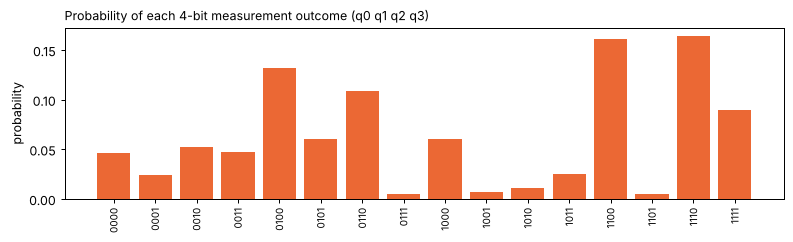

In [4]:
# The 16 measurement probabilities of the final state for this patch
state = None
def final_state(x, theta, L):
    s = np.zeros((1,) + (2,) * 4, dtype=complex); s[(0,) * 5] = 1
    for l in range(L):
        for q in range(4):
            s = qm._apply_1q(s, qm._ry(x[:, 2*q]), q); s = qm._apply_1q(s, qm._rz(x[:, 2*q+1]), q)
        for q in range(4):
            s = qm._apply_1q(s, qm._ry(theta[l, q, 0]), q); s = qm._apply_1q(s, qm._rz(theta[l, q, 1]), q)
        for q in range(4):
            s = qm._apply_cnot(s, q, (q + 1) % 4)
    return s.reshape(-1)
probs = np.abs(final_state(x, model.theta, model.n_layers)) ** 2
plt.figure(figsize=(9, 2.8))
plt.bar([format(b, "04b") for b in range(16)], probs, color="#eb6834")
plt.title("Probability of each 4-bit measurement outcome (q0 q1 q2 q3)", loc="left", fontsize=10)
plt.xticks(rotation=90, fontsize=8); plt.ylabel("probability"); plt.tight_layout(); plt.show()
print("sum of probabilities =", probs.sum().round(6))

## 3. Watching it learn (tiny demo)
90 training patches, 2 layers, 8 epochs. Each step computes the gradient of all 16 quantum angles with the **parameter-shift rule** (2 circuit runs per angle) and updates them with Adam.

In [5]:
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(y_train == k)[0], 30, replace=False) for k in range(3)])
demo = qm.VQC(n_layers=2, lr=0.1, epochs=8, batch_size=16, verbose=False)
print("loss before:", round(demo.loss(X_train[idx], y_train[idx]), 3))
demo.fit(X_train[idx], y_train[idx])
for h in demo.history:
    print(f"epoch {h['epoch']}: loss {h['train_loss']:.3f}  train acc {h['train_acc']:.2f}")

loss before: 1.375
epoch 1: loss 1.151  train acc 0.37
epoch 2: loss 1.077  train acc 0.44
epoch 3: loss 1.048  train acc 0.43
epoch 4: loss 0.998  train acc 0.56
epoch 5: loss 0.942  train acc 0.57
epoch 6: loss 0.897  train acc 0.68
epoch 7: loss 0.873  train acc 0.67
epoch 8: loss 0.856  train acc 0.67


## 4. Full experiment

`python qml/src/quantum_model.py` (≈20 min on a laptop CPU):

1. Holds out 20 % of the **training** road stretches as validation.
2. Tries layers ∈ {2, 3, 4} × learning rate ∈ {0.01, 0.03, 0.1}, up to 50 epochs each, keeps the best validation F1.
3. Retrains the chosen configuration on all 900 training patches for the chosen number of epochs.
4. Evaluates once on the 300 test patches.
5. Builds a QSVM with the fidelity kernel on the same 8 angles (C chosen by GroupKFold CV).

Set `RUN = True` to reproduce (or `--backend pennylane` from the command line).

In [6]:
RUN = False
if RUN:
    import subprocess
    subprocess.run([sys.executable, str(QML / "src" / "quantum_model.py")], check=True)
    subprocess.run([sys.executable, str(QML / "src" / "evaluation.py")], check=True)

sel = load("quantum_hyperparameter_selection")
print(pd.DataFrame(sel).T[["layers", "lr", "val_f1", "best_epoch", "time_s", "n_params"]].to_string())

                 layers    lr    val_f1 best_epoch      time_s n_params
layers=2,lr=0.01      2  0.01  0.633243         50   48.132644       22
layers=2,lr=0.03      2  0.03   0.65103         15   48.448069       22
layers=2,lr=0.1       2   0.1  0.654906         50   47.938276       22
layers=3,lr=0.01      3  0.01  0.655708         36  103.252198       30
layers=3,lr=0.03      3  0.03  0.628409         38  101.936046       30
layers=3,lr=0.1       3   0.1  0.691436         47  103.602034       30
layers=4,lr=0.01      4  0.01   0.64799         50  176.679997       38
layers=4,lr=0.03      4  0.03   0.67897         32  177.339205       38
layers=4,lr=0.1       4   0.1   0.66037          9  173.978031       38


VQC   test accuracy 0.593  precision 0.609  recall 0.593  F1 0.588  train 128.7s
QSVM  test accuracy 0.680  precision 0.689  recall 0.680  F1 0.681  train 0.1s
VQC configuration: {'n_qubits': 4, 'n_layers': 3, 'epochs': 47, 'learning_rate': 0.1, 'n_trainable_params': 30}


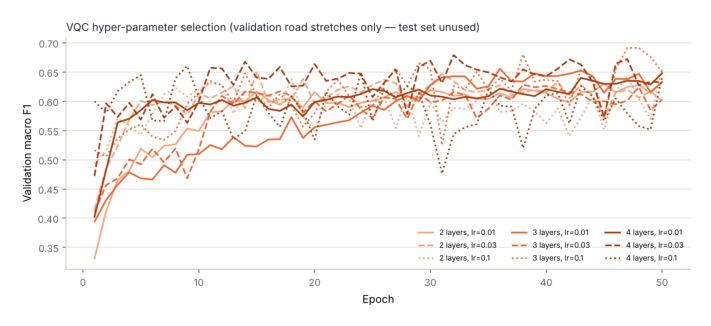

In [7]:
show(GRAPHS / "quantum_vqc_selection.png", width=10)
vqc, qsvm = load("quantum_vqc"), load("quantum_qsvm")
for name, m in [("VQC", vqc), ("QSVM", qsvm)]:
    print(f"{name:5s} test accuracy {m['accuracy']:.3f}  precision {m['precision_macro']:.3f}  "
          f"recall {m['recall_macro']:.3f}  F1 {m['f1_macro']:.3f}  train {m['train_time_s']:.1f}s")
print("VQC configuration:", {k: vqc[k] for k in ["n_qubits", "n_layers", "epochs", "learning_rate", "n_trainable_params"]})

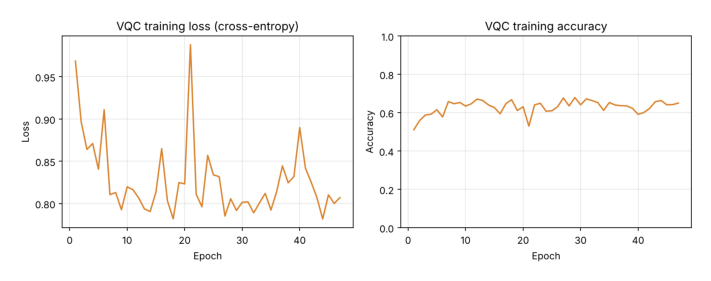

In [8]:
show(GRAPHS / "quantum_vqc_training_curve.png", width=10)

## 5. Classical vs quantum

In [9]:
print((METRICS / "comparison.md").read_text())

## Headline comparison

| Metric | Classical ML — best by CV, 16 features | Classical ML — best by CV, same 8 features | QML — VQC | QML — QSVM |
|---|---|---|---|---|
| Model | Classical: Random Forest, 16 features | Classical: SVM (RBF), same 8 features as QML | QML: VQC, 4 qubits, 3 layers | QML: QSVM, quantum kernel, 4 qubits |
| Accuracy | 0.730 | 0.703 | 0.593 | 0.680 |
| Precision (macro) | 0.746 | 0.714 | 0.609 | 0.689 |
| Recall (macro) | 0.730 | 0.703 | 0.593 | 0.680 |
| F1-score (macro) | 0.732 | 0.705 | 0.588 | 0.681 |
| Training time (s) | 0.44 | 0.02 | 128.71 | 0.06 |
| Inference time (ms/sample) | 0.181 | 0.020 | 0.028 | 0.043 |

## All models

| Model | Type | Accuracy | Precision | Recall | F1 | Training time (s) | Inference (ms/sample) |
|---|---|---|---|---|---|---|---|
| Logistic Regression (16 feat.) | Classical | 0.683 | 0.684 | 0.683 | 0.683 | 0.02 | 0.001 |
| Logistic Regression (8 PCA feat.) | Classical | 0.650 | 0.651 | 0.650 | 0.650 | 0.01 | 0.003 |
| SVM (RB

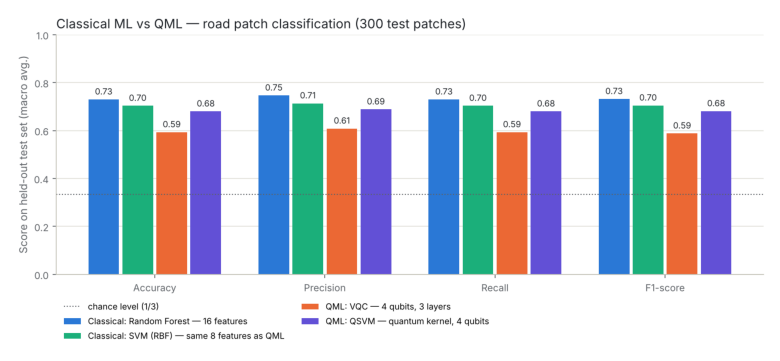

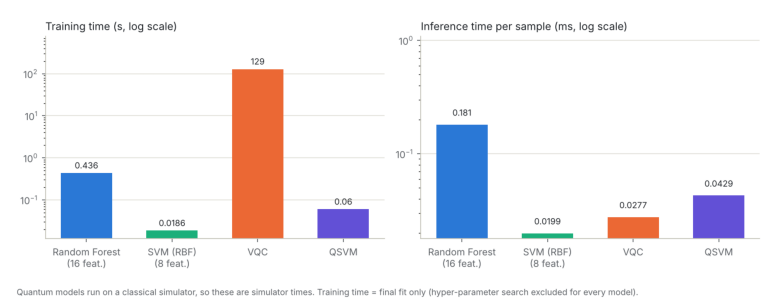

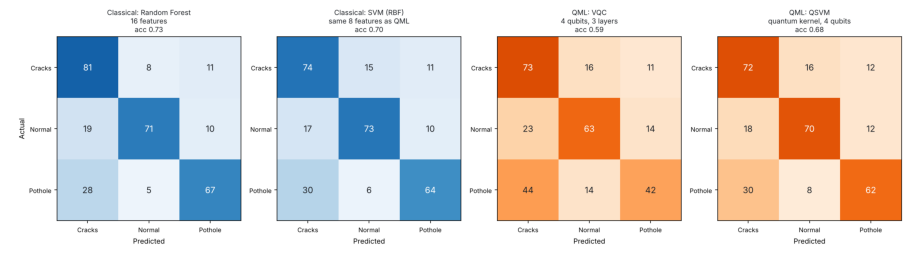

In [10]:
show(GRAPHS / "comparison_metrics.png", width=11)
show(GRAPHS / "comparison_time.png", width=11)
show(GRAPHS / "confusion_matrices.png", width=13)

### Robustness check: test on highways never seen in training

In [11]:
print((METRICS / "comparison_unseen_highway.md").read_text().split("## All models")[0])

## Headline comparison

| Metric | Classical ML — best by CV, 16 features | Classical ML — best by CV, same 8 features | QML — VQC | QML — QSVM |
|---|---|---|---|---|
| Model | Classical: Random Forest, 16 features | Classical: SVM (RBF), same 8 features as QML | QML: VQC, 4 qubits, 3 layers | QML: QSVM, quantum kernel, 4 qubits |
| Accuracy | 0.613 | 0.497 | 0.497 | 0.483 |
| Precision (macro) | 0.643 | 0.547 | 0.383 | 0.608 |
| Recall (macro) | 0.613 | 0.497 | 0.497 | 0.483 |
| F1-score (macro) | 0.575 | 0.454 | 0.415 | 0.463 |
| Training time (s) | 0.36 | 0.02 | 136.72 | 0.05 |
| Inference time (ms/sample) | 0.080 | 0.019 | 0.022 | 0.039 |




Discussion of which model is better, whether QML is competitive, limitations and next steps: **`qml/docs/05_results_and_discussion.md`**.